In [1]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import random
seed = 42
random.seed(seed)
np.random.seed(seed)
torch.manual_seed(seed)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(seed)

from FEX.utils import fex
device = 'cuda' if torch.cuda.is_available() else 'cpu'

import sys
import os

project_root = os.path.abspath(os.path.join(os.getcwd(), '..', '..')) 
if project_root not in sys.path:
    sys.path.append(project_root)

In [ ]:
from generate_data import make_adjacency, make_data
num_traj = 5
timesteps=1000
adj_matrix = make_adjacency(100, 2, 7)
data, derivatives, omegas = make_data(num_trajectories=num_traj, num_timesteps=timesteps, adjacency=adj_matrix, coupling=0.15, snr=45, smoothing=True)

In [3]:
dimx_fex = fex.CoupledFEX('depth_4_partial_config', 'depth_2_tree_config', 0, controller_epochs = 200, inter_lr=0.02, self_lr=0.02, num_fex_epochs = 100, finetune_epochs=10000, finetune_lr=1e-4, poolsize=8, device=device, expression_threshold=0.01)
dimx_fex.fit(data, derivatives, adj_matrix, num_workers=5)

Using 5 parallel processes for candidate evaluation.
Evaluating candidate 1 on GPU 0
Evaluating candidate 2 on GPU 0
Evaluating candidate 0 on GPU 0
Evaluating candidate 3 on GPU 0
Evaluating candidate 4 on GPU 0
Evaluating candidate 5 on GPU 0
Evaluating candidate 6 on GPU 0
Evaluating candidate 7 on GPU 0
Evaluating candidate 8 on GPU 0
Evaluating candidate 9 on GPU 0
Evaluation time for fex epoch: 0.24 seconds
Epoch 0 pmfs: [array([[0.36521876, 0.32198614, 0.3127951 ]], dtype=float32), array([[0.36855784, 0.2891681 , 0.34227407]], dtype=float32), array([[0.34471038, 0.31646296, 0.33882663]], dtype=float32), array([[0.14378785, 0.13514373, 0.13292617, 0.1432008 , 0.15699928,
        0.14358012, 0.14436208]], dtype=float32), array([[0.1544921 , 0.14406146, 0.13309185, 0.14550507, 0.13309048,
        0.1543371 , 0.13542193]], dtype=float32), array([[0.12233458, 0.14408538, 0.17021261, 0.14187616, 0.14097562,
        0.13842936, 0.1420863 ]], dtype=float32), array([[0.13550758, 0.141011

AcceleratorError: CUDA error: unknown error
Search for `cudaErrorUnknown' in https://docs.nvidia.com/cuda/cuda-runtime-api/group__CUDART__TYPES.html for more information.
For more detailed error information, run with CUDA_LOG_FILE=stderr


In [ ]:
dimy_fex = fex.SingleFEX('depth_4_partial_config', 1, controller_epochs = 150, self_lr=0.02, num_fex_epochs = 80, num_finetune_epochs=10000, finetune_lr=1e-4, poolsize=8, device=device, expression_threshold=0.01)
dimy_fex.fit(data, derivatives, num_workers=5)

Using 5 parallel processes for candidate evaluation.


Evaluating candidate 3 on GPU 0
Evaluating candidate 2 on GPU 0
Evaluating candidate 1 on GPU 0
Evaluating candidate 0 on GPU 0
Evaluating candidate 4 on GPU 0
Evaluating candidate 5 on GPU 0
Evaluating candidate 6 on GPU 0
Evaluating candidate 7 on GPU 0
Evaluating candidate 8 on GPU 0
Evaluating candidate 9 on GPU 0
Evaluation time for fex epoch: 0.20 seconds
Epoch 0, pmfs: [array([[0.31390676, 0.33207163, 0.35402158]], dtype=float32), array([[0.3575448 , 0.32654667, 0.31590855]], dtype=float32), array([[0.33824039, 0.3174718 , 0.3442878 ]], dtype=float32), array([[0.1234092 , 0.1484177 , 0.16211987, 0.12641726, 0.14542447,
        0.15131474, 0.14289677]], dtype=float32), array([[0.15292248, 0.14445432, 0.1396359 , 0.12278367, 0.13774522,
        0.1543455 , 0.14811292]], dtype=float32), array([[0.1576302 , 0.13679597, 0.13793881, 0.14189182, 0.14244497,
        0.13658331, 0.14671496]], dtype=float32), array([[0.12667178, 0.15165292, 0.1561995 , 0.14770451, 0.12888229,
        0.15

In [ ]:
print(dimx_fex)
print(dimy_fex)

FEX(self_fex=0.00187606549823335*x1**4 - 0.00435069508038982*x1**3*x2 - 0.974920735519637*x1**3 + 0.00378351250056647*x1**2*x2**2 + 0.00147707310438255*x1**2*x2 - 0.00183359481408379*x1**2 - 0.0014623244857101*x1*x2**3 - 0.977365549704894*x1*x2**2 + 0.00213843948027206*x1*x2 + 0.978400508781908*x1 + 0.00259067131593277*x2**3 - 1.00282137814056*x2 
inter_fex=0.147541292813249*exp(-1.0041*x1 + 0.0016*x2 + 1.0079*x3) - 0.1475)
FEX = ((0.916952140016437*exp(0.34*x1) + exp(0.1735*x2))*(0.0725297900356518*x1**3 - 0.737821192529512*x1**2*x2 + 0.28240218912059*x1*x2**2 - 0.887121867125139*x2**3 + 1.2832*sin(0.7262*x1 + 0.8062*x2 + 0.0016) + 0.4577) - 0.8805*exp(0.1735*x2))/(0.916952140016437*exp(0.34*x1) + exp(0.1735*x2))


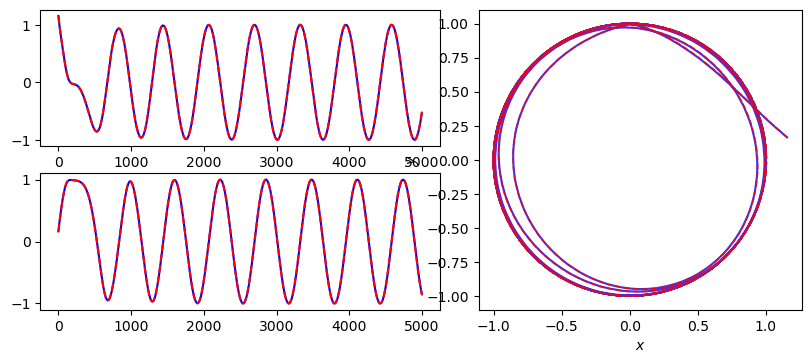

In [ ]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from FEX.utils.fex import simulate

dt = 0.01

plot_timesteps=5000
adj_matrix = make_adjacency(100, 2, 7)
plot_data, plot_derivatives, _ = make_data(num_trajectories=1, num_timesteps=plot_timesteps, adjacency=adj_matrix, coupling=0.15, snr=60)

x0 = plot_data[0]
pred_traj, pred_derivatives = simulate([dimx_fex, dimy_fex], x0, adj_matrix, plot_timesteps, dt)
true = plot_data.detach().cpu()
pred = pred_traj.detach().cpu()

true = true[:plot_timesteps]
pred = pred[:plot_timesteps]

time = np.arange(plot_timesteps) * dt

x_true = true[:, :, 0].numpy()
y_true = true[:, :, 1].numpy()

x_pred = pred[:, :, 0].numpy()
y_pred = pred[:, :, 1].numpy()

A = adj_matrix.detach().cpu().numpy()

avg_degree = A.sum() / A.shape[0]


# Ground-truth parameters
lambda_ = 1.0
omega = 1.0
b = 0.5
coupling = 0.1

nodes_to_plot = [15] # [0] #, 1 , 2, 3]


# Figure

fig = plt.figure(figsize=(8, 5))
grid_left = plt.GridSpec(2, 1, left=0.0, right=0.5, top=0.8, bottom=0.2)
x_ax_plot = fig.add_subplot(grid_left[0, 0])
y_ax_plot = fig.add_subplot(grid_left[1, 0])
grid_right = plt.GridSpec(1, 1, left=0.5, right=1.0, top=0.8, bottom=0.2)
x_y_ax_plot = fig.add_subplot(grid_right[0, 0])

x_ax_plot.plot(x_true[:, nodes_to_plot[0]], color="blue")
x_ax_plot.plot(x_pred[:, nodes_to_plot[0]], linestyle="--", color="red")
y_ax_plot.plot(y_true[:, nodes_to_plot[0]], color="blue")
y_ax_plot.plot(y_pred[:, nodes_to_plot[0]], linestyle="--", color="red")

for node in nodes_to_plot:
    x_y_ax_plot.plot(
        x_true[:, node],
        y_true[:, node],
        linewidth=1.5,
        color="blue",
        alpha=0.8
    )

    x_y_ax_plot.plot(
        x_pred[:, node],
        y_pred[:, node],
        linestyle="--",
        color="red",
        linewidth=1.2,
        alpha=0.8
    )

x_y_ax_plot.set_xlabel(r"$x$")
x_y_ax_plot.set_ylabel(r"$y$")
x_y_ax_plot.set_aspect("equal", adjustable="box")